# 06 — dN/dz of emitters above the flux limit (no confusion, no downsampling)

A census of the mock with only three cuts: the line flux exceeds the limit (1.0e-16 or 1.5e-16 erg/s/cm²),
the observed line wavelength falls in the Roman grism range (1.00–1.93 μm), and 0.5 < z < 3.0. No confusion
matrix, no interlopers, no downsampling. This is the population the Wang et al. (2022) tables describe
(true emitters above the flux limit, "observational efficiency not included"), so it is the cleanest
mock-versus-forecast comparison.

Each line is counted separately, and galaxies are split by the number of lines of the set that pass the
cut: exactly one (single-line galaxies, whose redshift would rely on line identification) or more than one
(multi-line galaxies). `romanmock.census` does the counting slice by slice, in parallel, reusing the pipeline's
flux and detection code. Run it on a compute node (`sbatch scripts/execute_notebooks.sh 06`) or on a login
node with a few workers (~15 s per slice per worker).

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # diffsky imports JAX; avoid CUDA probing on login nodes
import warnings
warnings.filterwarnings("ignore", message="Version checking")

import numpy as np
import matplotlib.pyplot as plt
import opencosmo as oc

from romanmock import plotting
plotting.use_style()

CATALOG = "/global/cfs/cdirs/m4943/Simulations/sdss_feniks_hizels_260710_09_07_2026"
WORK = os.path.join(os.environ.get("PSCRATCH", "/tmp"), "romanmock_demo")   # outputs of the tutorials
os.makedirs(WORK, exist_ok=True)

In [2]:
import time
from romanmock.census import LineCensus, line_census
from romanmock.io import select_files, suggest_n_workers, memory_budget_gb, open_catalog
from romanmock.reference_dndz import wang2022_bins, wang2022_errors, WANG2022_CITATION
from romanmock.roman import GRISM_WAVE_RANGE_ANGSTROM
from romanmock.selection import sky_area_deg2

FLUX_LIMITS = [1.0e-16, 1.5e-16]                              # erg/s/cm², both tabulated by Wang et al. (2022)
Z_EDGES = np.round(np.arange(0.5, 3.0 + 1e-9, 0.1), 2)         # the tables' 0.1-wide bins
ZC = 0.5 * (Z_EDGES[1:] + Z_EDGES[:-1])
# every line of the set is counted; lines with no galaxy above the limit are left out of the legends and table
CENSUS_FILE = os.path.join(WORK, "census_z0p5_3p0.npz")

files = select_files(CATALOG, z_min=Z_EDGES[0], z_max=Z_EDGES[-1])
N_WORKERS = suggest_n_workers(max_workers=32, per_worker_gb=4.0)
print(f"{len(files)} slices overlap 0.5 < z < 3.0; memory budget {memory_budget_gb():.0f} GB -> {N_WORKERS} worker(s)")
print(f"bandpass {GRISM_WAVE_RANGE_ANGSTROM} Å; binned in redshift_obs (peculiar velocity included), D_L at redshift_true")

42 slices overlap 0.5 < z < 3.0; memory budget 480 GB -> 32 worker(s)
bandpass (10000.0, 19300.0) Å; binned in redshift_obs (peculiar velocity included), D_L at redshift_true


In [3]:
if os.path.exists(CENSUS_FILE):
    census = LineCensus.load(CENSUS_FILE)
    print(f"loaded {CENSUS_FILE} ({len(census.steps)} slices)")
else:
    t0 = time.time()
    census = line_census(CATALOG, FLUX_LIMITS, Z_EDGES, line_set="roman_transitions", n_workers=N_WORKERS, verbose=False)
    census.save(CENSUS_FILE)
    print(f"{len(census.steps)} slices in {(time.time() - t0) / 60:.1f} min -> {CENSUS_FILE}")
print(f"{census.n_all.sum():,} galaxies with 0.5 < z < 3.0")

loaded /pscratch/sd/w/willlake/romanmock_demo/census_z0p5_3p0.npz (42 slices)
273,487,492 galaxies with 0.5 < z < 3.0


## Sky area

Occupied HEALPix pixels of the input lightcone at the finest index level, edge pixels counted half. All
slices in the redshift range are opened together (a single slice is too sparse: empty pixels inside the
footprint would be mistaken for edges and bias the area low by a few per cent).

In [4]:
t0 = time.time()
area = sky_area_deg2(open_catalog(files))
print(f"area = {area:.1f} deg² (nominal 5 % of the sky = {0.05 * 41252.96:.1f}), {time.time() - t0:.0f} s")

area = 2063.3 deg² (nominal 5 % of the sky = 2062.6), 43 s


## dN/dz per line at both flux limits

Solid steps: the mock. Dashed and dotted steps with shaded ±1σ bands: Wang et al. (2022) Tables 1–2 (Galacticus)
for Hα and [O III] 5007 at the same flux limit, for their two dust models, A_V = 1.65 (dashed) and A_V = 1.92
(dotted); the tabulated uncertainties combine jackknife resampling and cosmic variance. Every galaxy with the line above the limit is counted, whatever its other lines do. All nine lines of
the `roman_transitions` set are counted; lines with fewer than one galaxy per deg² above the limit (the auroral
[O III] 4363, never, and [S III] 6312, ~150 galaxies in the whole footprint) are left out of the legends and the table.

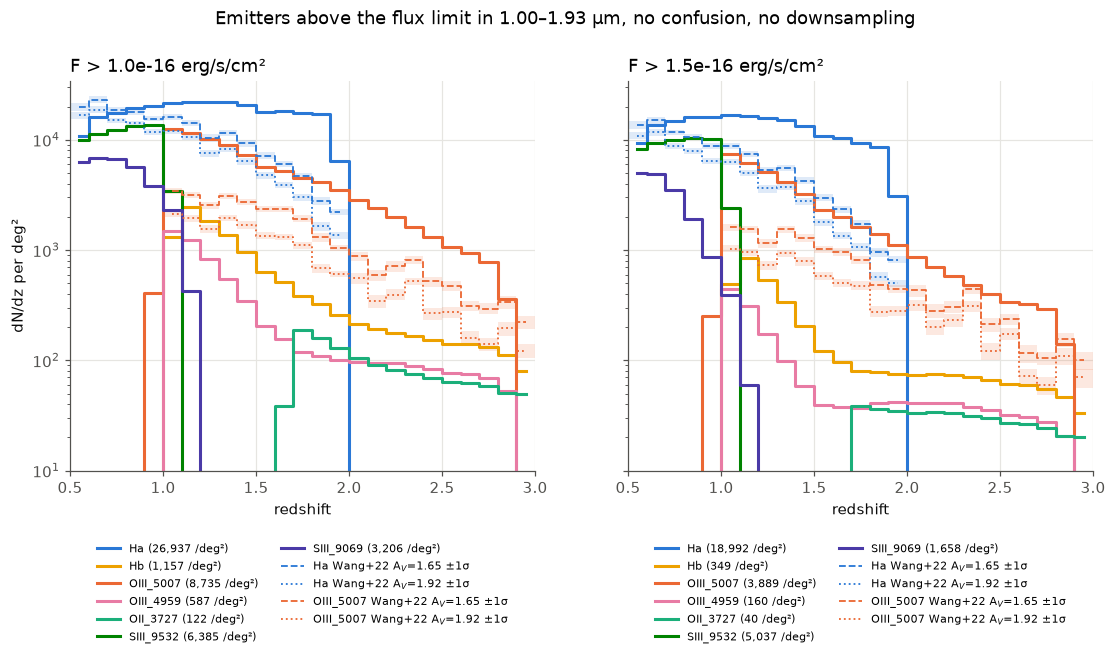

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, lim in zip(axes, FLUX_LIMITS):
    for name in census.line_names:
        y = census.dndz(name, lim, area)
        if census.integrated(name, lim, area) < 1:          # auroral lines: a handful of galaxies in the whole footprint
            continue
        ax.step(ZC, y, where="mid", color=plotting.feature_color(name), label=f"{name} ({census.integrated(name, lim, area):,.0f} /deg²)")
    for name in ["Ha", "OIII_5007"]:
        for dust_av, ls in [(1.65, "--"), (1.92, ":")]:
            edges, ref = wang2022_bins(name, lim, dust_av)
            err = wang2022_errors(name, lim, dust_av)
            zc_ref = 0.5 * (edges[1:] + edges[:-1])
            ax.step(zc_ref, ref, where="mid", color=plotting.feature_color(name), ls=ls, lw=1.2,
                    label=f"{name} Wang+22 A$_V$={dust_av} ±1σ")
            ax.fill_between(edges, np.append(ref - err, ref[-1] - err[-1]), np.append(ref + err, ref[-1] + err[-1]),
                            step="post", color=plotting.feature_color(name), alpha=0.15, lw=0)
    ax.set_yscale("log"); ax.set_ylim(10, None); ax.set_xlim(Z_EDGES[0], Z_EDGES[-1])
    ax.set_xlabel("redshift"); ax.set_title(f"F > {lim:.1e} erg/s/cm²")
    ax.legend(fontsize=7.5, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.16), frameon=False)
axes[0].set_ylabel("dN/dz per deg²")
fig.suptitle("Emitters above the flux limit in 1.00–1.93 μm, no confusion, no downsampling", y=1.02)
plt.show()

In [6]:
# integrated counts over 0.5 < z < 3.0: per deg² and over the whole footprint
from astropy.table import Table

rows = []
for lim in FLUX_LIMITS:
    for name in census.line_names:
        tot = census.integrated(name, lim, area)
        if tot < 1:
            continue
        single = census.integrated(name, lim, area, "single")
        rows.append({"flux_limit": f"{lim:.1e}", "line": name, "N/deg²": round(tot), "single-line /deg²": round(single),
                     "multi-line /deg²": round(tot - single), "single fraction": round(single / tot, 3),
                     "N total": int(census.hist(name, lim).sum())})
table = Table(rows=rows)
table.write(os.path.join(WORK, "census_z0p5_3p0.csv"), format="csv", overwrite=True)
table

flux_limit,line,N/deg²,single-line /deg²,multi-line /deg²,single fraction,N total
str7,str9,int64,int64,int64,float64,int64
1.0e-16,Ha,26937,13858,13079,0.514,55578023
1.0e-16,Hb,1157,7,1150,0.006,2386659
1.0e-16,OIII_5007,8735,1387,7348,0.159,18023335
1.0e-16,OIII_4959,587,0,587,0.0,1211276
1.0e-16,OII_3727,122,1,121,0.011,252188
1.0e-16,SIII_9532,6385,95,6290,0.015,13174759
1.0e-16,SIII_9069,3206,0,3206,0.0,6614938
1.5e-16,Ha,18992,10901,8091,0.574,39184472
1.5e-16,Hb,349,3,346,0.008,720042


## Single-line versus multi-line galaxies

For each line: all galaxies with the line above the limit (solid), those with **only** that line above the
limit inside the bandpass (dashed), and those with at least one other line above it (dotted). The single-line
population is the one exposed to misidentification; the multi-line one gets an unambiguous redshift.

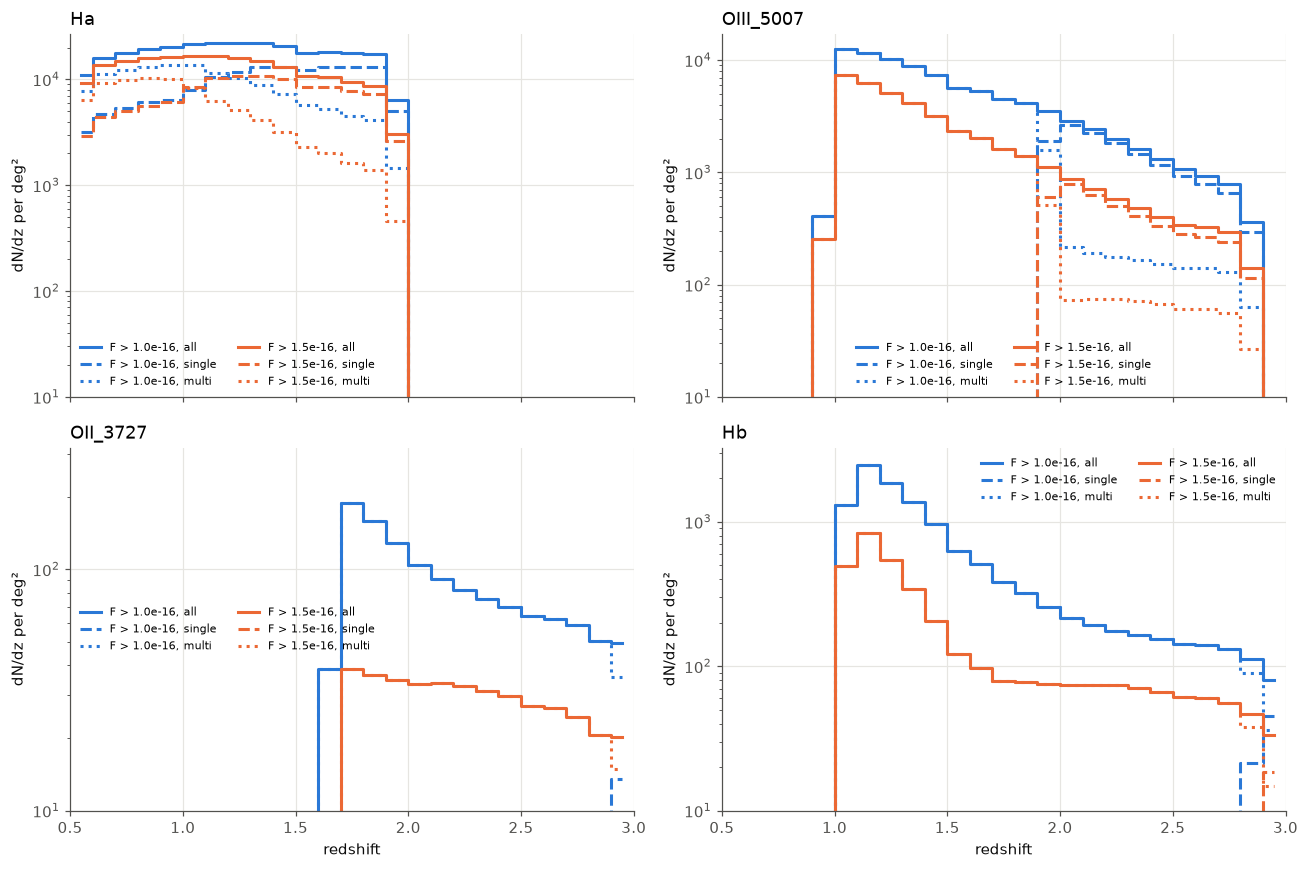

In [7]:
SHOW = ["Ha", "OIII_5007", "OII_3727", "Hb"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, name in zip(axes.ravel(), SHOW):
    for lim, col in zip(FLUX_LIMITS, [plotting.CATEGORICAL[0], plotting.CATEGORICAL[1]]):
        for which, ls in [("all", "-"), ("single", "--"), ("multi", ":")]:
            y = census.dndz(name, lim, area, which)
            ax.step(ZC, y, where="mid", color=col, ls=ls, label=f"F > {lim:.1e}, {which}")
    ax.set_yscale("log"); ax.set_ylim(10, None); ax.set_xlim(Z_EDGES[0], Z_EDGES[-1])
    ax.set_title(name); ax.set_ylabel("dN/dz per deg²")
    ax.legend(fontsize=7, ncol=2)
for ax in axes[1]:
    ax.set_xlabel("redshift")
plt.tight_layout(); plt.show()

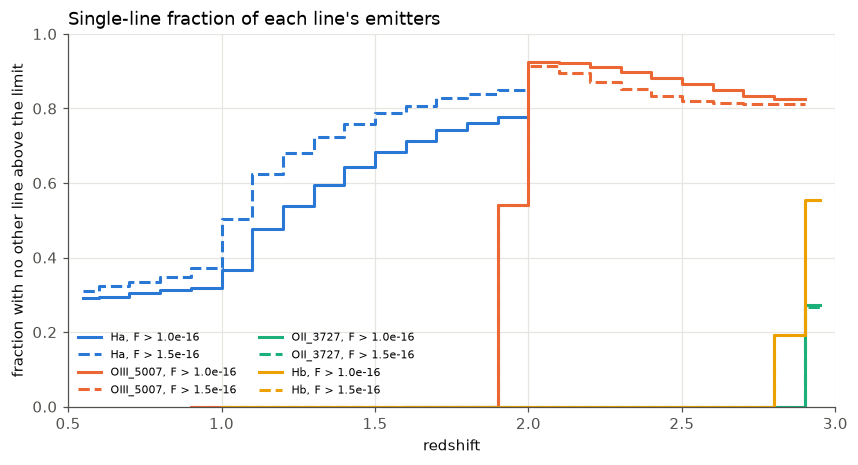

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for name in SHOW:
    for lim, ls in zip(FLUX_LIMITS, ["-", "--"]):
        ax.step(ZC, census.single_fraction(name, lim), where="mid", color=plotting.feature_color(name), ls=ls,
                label=f"{name}, F > {lim:.1e}")
ax.set_ylim(0, 1); ax.set_xlim(Z_EDGES[0], Z_EDGES[-1])
ax.set_xlabel("redshift"); ax.set_ylabel("fraction with no other line above the limit")
ax.set_title("Single-line fraction of each line's emitters"); ax.legend(fontsize=7.5, ncol=2); plt.show()

Reading the single-line fraction: at z < 1 most Hα emitters also have [S III] 9532 (and 9069) above the limit,
so only ~30 % are single-line. Once the [S III] lines leave the grism (z ≈ 1.0–1.1) the remaining companions,
[O III] 5007 and Hβ, pass the flux cut for a minority of Hα emitters, and the single-line fraction climbs to
~0.8–0.85 by z ≈ 1.9. [O III] 5007 emitters are almost never single-line while Hα is in the bandpass (z < 1.94),
and ~85–90 % single-line beyond it, where only Hβ, [O III] 4959 and [O II] could accompany the line.

## Ratio to the Wang et al. (2022) forecast

Mock over forecast per 0.1 bin, for the total population of each line (the tables do not split by line multiplicity).
Error bars propagate the tabulated ±1σ of the forecast; the mock's own Poisson error is negligible in comparison.

Ha         F > 1.0e-16: mock/Wang+22 over 0.5 < z < 2.0 = 1.50  (per-bin range 0.55–6.20)
Ha         F > 1.5e-16: mock/Wang+22 over 0.5 < z < 2.0 = 1.90  (per-bin range 0.68–9.09)
OIII_5007  F > 1.0e-16: mock/Wang+22 over 1.0 < z < 3.0 = 2.98  (per-bin range 0.00–4.06)
OIII_5007  F > 1.5e-16: mock/Wang+22 over 1.0 < z < 3.0 = 2.92  (per-bin range 0.00–4.61)


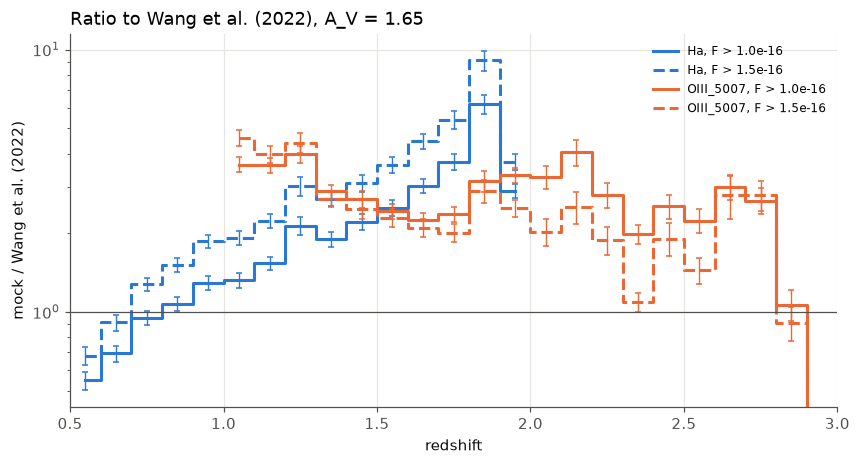

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for name in ["Ha", "OIII_5007"]:
    for lim, ls in zip(FLUX_LIMITS, ["-", "--"]):
        edges, ref = wang2022_bins(name, lim)
        zc_ref = np.round(0.5 * (edges[1:] + edges[:-1]), 3)
        mock = census.dndz(name, lim, area)
        sel = np.isin(np.round(ZC, 3), zc_ref)
        ratio = mock[sel] / ref
        ratio_err = ratio * wang2022_errors(name, lim) / ref
        ax.step(zc_ref, ratio, where="mid", color=plotting.feature_color(name), ls=ls, label=f"{name}, F > {lim:.1e}")
        ax.errorbar(zc_ref, ratio, yerr=ratio_err, fmt="none", ecolor=plotting.feature_color(name), elinewidth=0.9, capsize=2)
        lo, hi = edges[0], edges[-1]
        print(f"{name:10s} F > {lim:.1e}: mock/Wang+22 over {lo:.1f} < z < {hi:.1f} = "
              f"{census.integrated(name, lim, area, z_range=(lo, hi)) / (ref * np.diff(edges)).sum():.2f}  "
              f"(per-bin range {ratio.min():.2f}–{ratio.max():.2f})")
ax.axhline(1, color=plotting.TEXT_SECONDARY, lw=0.8)
ax.set_yscale("log"); ax.set_xlim(Z_EDGES[0], Z_EDGES[-1])
ax.set_xlabel("redshift"); ax.set_ylabel("mock / Wang et al. (2022)")
ax.set_title("Ratio to Wang et al. (2022), A_V = 1.65"); ax.legend(fontsize=8); plt.show()

Files written to `WORK`: `census_z0p5_3p0.npz` (all counts, reloadable with `LineCensus.load`) and
`census_z0p5_3p0.csv` (the integrated table). To add a flux limit or change the bins, delete the `.npz` and rerun;
`line_census` accepts any list of limits, tabulated or not.